# Importing Libraries

In [1]:
import hickle
import pandas as pd
import scipy.signal
# import shap
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.ticker import FormatStrFormatter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
# from astropy.table import Table
from scipy import ndimage
from tqdm import tqdm
import corner
from PIL import Image
import io

import os

import torch
from torch import nn, optim
from torch.utils.data import Dataset, DataLoader
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

from scipy.stats import chi2
from sklearn.datasets import make_s_curve
import matplotlib as mpl
import matplotlib.pyplot as plt
import tqdm

import ili
from ili.dataloaders import NumpyLoader
from ili.inference import InferenceRunner
from ili.validation.metrics import PosteriorCoverage, PlotSinglePosterior

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

from datasets import load_dataset, DatasetDict
from transformers import ViTFeatureExtractor, ViTForImageClassification, ViTModel, AdamW, AutoImageProcessor, AutoModel
from sklearn.metrics import r2_score
from scipy.stats import spearmanr
from tqdm import tqdm

Device: cuda


/home/juanpabloalfonzo/anaconda3/envs/ili-torch2/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


INFO:datasets:PyTorch version 2.6.0 available.


# Importing Data From Saved Models

In [2]:
def check_degeneracy(samples, vb=False):

    covs = np.zeros((samples.shape[1],samples.shape[1]))
    pvals = np.ones((samples.shape[1],samples.shape[1]))
    for i in range(samples.shape[1]):
        for j in range(i):
            covs[i,j], pvals[i,j] = spearmanr(samples[:,i], samples[:,j])

    if vb==True:
        plt.imshow(np.abs(covs[1:,:-1]));
        plt.xticks(np.arange(5), labels[0:5])
        plt.yticks(np.arange(5), labels[1:])
        plt.colorbar(); plt.show()
        
        plt.imshow(np.abs((pvals<0.05)[1:,:-1]))
        plt.xticks(np.arange(5), labels[0:5])
        plt.yticks(np.arange(5), labels[1:])
        plt.colorbar(); plt.show()

    return covs[1:,:-1], pvals[1:,:-1]

In [3]:
GSWLC_data = load_dataset('juanpabloalfonzo/GSWLC_Data',split='train')
gswlc_data = pd.DataFrame(GSWLC_data)

gswlc_images = load_dataset('juanpabloalfonzo/GSWLC_Images',split='train')
gswlc_images = gswlc_images['images'].copy()

In [4]:
temp_fuv = np.array(gswlc_data['FUV']).copy()
temp_fuv[temp_fuv > 25] = 25 + 0.3*np.random.normal(size=(np.sum(temp_fuv>25),))

temp_w2 = np.array(gswlc_data['W2']).copy()
temp_w2[temp_w2 > 23] = 23

temp_w3 = np.array(gswlc_data['W3']).copy()
temp_w3[temp_w3 > 23] = 23 + 0.3*np.random.normal(size=(np.sum(temp_w3>23),))

temp_w4 = np.array(gswlc_data['W4']).copy()
temp_w4[temp_w4 > 23] = 23 + 0.3*np.random.normal(size=(np.sum(temp_w4>23),))

eleven_bands_SED = np.array((temp_fuv, 
               gswlc_data['NUV'],
               gswlc_data['u'],
               gswlc_data['g'],
               gswlc_data['r'],
               gswlc_data['i'],
               gswlc_data['z'],
               gswlc_data['W1'],
               temp_w2,
               temp_w3,
               temp_w4,)).T

tempt50 = np.array(gswlc_data['t_50']).copy()
tempt50[(tempt50 > 13.7)] = 13.7

tempssfr = np.array(gswlc_data['logSSFR_50']).copy()
tempssfr[tempssfr < -3.5] = tempssfr[tempssfr < -3.5] + 0.3*np.random.normal(size=(np.sum(tempssfr < -3.5),))

tempmet = np.array(gswlc_data['logOH_50']).copy()
tempmet[tempmet < 7.1] = tempmet[tempmet < 7.1] + 0.1*np.random.normal(size=(np.sum(tempmet < 7.1),))

theta = np.vstack((gswlc_data['logM_50_x'], 
                   tempssfr,
                   gswlc_data['specz'],
                   tempt50,
                   gswlc_data['tauV_50'],
                   tempmet)).T
                #    manga_scalars['sersic_n'])).T
theta[np.isnan(theta)] = 0.

five_bands_SED= np.array((
               gswlc_data['u'],
               gswlc_data['g'],
               gswlc_data['r'],
               gswlc_data['i'],
               gswlc_data['z'],
               )).T



In [5]:
posterior_ensemble_sed_5_bands , summaries_sed_5_bands = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/clean_trained_ILIs/trained_ILI_5_bands_SED_train_set.hickle')
posterior_ensemble_sed , summaries_sed = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/clean_trained_ILIs/trained_ILI_11_bands_SED_train_set.hickle')
posterior_ensemble_im, summaries_im = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/clean_trained_ILIs/trained_ILI_images_train_set.hickle')
gswlc_embeds =  hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/ViT_embeds/gswlc_emebds_clean.hickle')
train_index = int(0.8*len(gswlc_data))

In [ ]:
clrs = plt.cm.Spectral(np.linspace(0,1,10))
ranges = [(9,12),(-15,-8),(0,0.15),(0,13.7),(0,3),(-1.5,0.25)]
labels = ['log M$_*$', 'log SFR','redshift','t50','Av','Z']

all_covs_sed, all_samples_sed = [], []
all_covs_im, all_samples_im = [], []

for gid in tqdm(range(train_index, len(gswlc_data))):
    xobs_sed = eleven_bands_SED[gid,:]
    xobs_im = gswlc_embeds[gid,:]
    x_truth = theta[gid,:]

    posterior_samples_sed = posterior_ensemble_sed.sample((1000,), torch.Tensor(xobs_sed).to(device), show_progress_bars = False)
    posterior_samples_sed = posterior_samples_sed.cpu().numpy()
    covs_sed, _ = check_degeneracy(posterior_samples_sed)

    posterior_samples_im = posterior_ensemble_im.sample((1000,), torch.Tensor(xobs_im).to(device), show_progress_bars = False)
    posterior_samples_im = posterior_samples_im.cpu().numpy()
    covs_im, _ = check_degeneracy(posterior_samples_im)

    all_covs_sed.append(covs_sed)
    all_samples_sed.append(posterior_samples_sed)
    all_covs_im.append(covs_im)
    all_samples_im.append(posterior_samples_im)

all_covs_sed_5_bands, all_samples_sed_5_bands = [], []

for gid in tqdm(range(train_index, len(gswlc_data))):
    xobs_sed = five_bands_SED[gid,:]
    # xobs_sed = five_bands_SED[gid,:]
    # xobs_im = infer(Image.open(io.BytesIO(gswlc_images[gid])))
    xobs_im = gswlc_embeds[gid,:]
    x_truth = theta[gid,:]

    posterior_samples_sed_5_bands = posterior_ensemble_sed_5_bands.sample((1000,), torch.Tensor(xobs_sed).to(device), show_progress_bars = False)
    posterior_samples_sed_5_bands = posterior_samples_sed_5_bands.cpu().numpy()
    covs_sed_5_bands, _ = check_degeneracy(posterior_samples_sed_5_bands)

    all_covs_sed_5_bands.append(covs_sed_5_bands)
    all_samples_sed_5_bands.append(posterior_samples_sed_5_bands)

In [7]:
#Loading the saved samples and covariances that are generated from the cell above
all_covs_sed, all_samples_sed = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/samples_and_covs/11_bands_SED_samples_and_covs.hickle')
all_covs_im, all_samples_im = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/samples_and_covs/images_samples_and_covs.hickle')

cov_array_sed = np.array(all_covs_sed)
cov_array_im = np.array(all_covs_im)
cov_array_sed.shape, cov_array_im.shape

all_covs_sed_5_bands, all_samples_sed_5_bands = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/samples_and_covs/5_bands_SED_samples_and_covs.hickle')

cov_array_sed_5_bands = np.array(all_covs_sed_5_bands)
cov_array_sed_5_bands.shape

train_index = int(0.8*len(gswlc_data))
sample_size = len(gswlc_data) - train_index

In [ ]:
morph_data = pd.read_csv('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/matched_morph_data_v4.csv')

if 'ID' not in gswlc_data.columns:
        print("\nError: 'ID' column not found in gswlc_data.")
elif 'ID' not in morph_data.columns:
    print("\nError: 'ID' column not found in morph_data.")
# Check if 'sersic_n_morph' exists in morph_data
elif 'bt_morph' not in morph_data.columns:
        print("\nError: 'bt_morph' column not found in morph_data.")
else:
    # Optional: Ensure 'ID' columns have the same data type if needed
    # gswlc_data['ID'] = gswlc_data['ID'].astype(int)
    # morph_data['ID'] = morph_data['ID'].astype(int)
    print("\nData loaded successfully. Proceeding with merge...")

    # --- Perform the left merge ---
    # We select only the 'ID' and 'sersic_n_morph' columns from morph_data
    gswlc_data_merged = pd.merge(gswlc_data, morph_data[['ID', 'pbulge_morph','bt_morph','half_light_radius_morph', 'bulge_n_morph', 'disk_n_morph', 'ttype_morph', 'pbar_morph', 'pdisk_morph', 'pedgeon_morph', 'pmerger_morph']], on='ID', how='left')

    # --- Display results ---
    print("\nMerge complete. Updated gswlc_data DataFrame head:")
    print(gswlc_data_merged.head())

    # Check for NaN values in the new column
    print("\nNumber of NaN values in 'bulge_n_morph' after merge:")
    print(gswlc_data_merged['bulge_n_morph'].isnull().sum())

    # You might want to assign the merged result back or use the new DataFrame:
    # gswlc_data = gswlc_data_merged

sersic_n = np.array(gswlc_data_merged['bulge_n_morph'][train_index:])
bt = np.array(gswlc_data_merged['bt_morph'][train_index:])
pbulge = np.array(gswlc_data_merged['pbulge_morph'][train_index:])
ttype= np.array(gswlc_data_merged['ttype_morph'][train_index:])
pbar = np.array(gswlc_data_merged['pbar_morph'][train_index:])
pdisk = np.array(gswlc_data_merged['pdisk_morph'][train_index:])
pedgeon = np.array(gswlc_data_merged['pedgeon_morph'][train_index:])
pmerger = np.array(gswlc_data_merged['pmerger_morph'][train_index:])


In [32]:
mvals = theta[train_index:,0]
sfrvals = theta[train_index:,1] + theta[train_index:,0] - 9

In [34]:
nqty = 6
allsederr, allimerr, allsedstd, allimstd = [], [], [], []

allimerr_raw = []
allsederr_raw = []
allimpred, allsedpred = [], []

target_sed = all_samples_sed_5_bands

for gid in range(sample_size):
    
    sed_err, im_err, sed_std, im_std, sed_err_raw, im_err_raw, im_pred, sed_pred = np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,))
    
    for i in range(nqty):
            
        q1_im = (all_samples_im[gid][:,i] - theta[train_index+gid, i])
        q1_sed = (target_sed[gid][:,i] - theta[train_index+gid, i])
        sed_err[i] = np.nanmean(np.sqrt(q1_sed**2))
        sed_std[i] = np.nanstd(q1_sed)
        im_err[i] = np.nanmean(np.sqrt(q1_im**2))
        im_std[i] = np.nanstd(q1_im)
        im_err_raw[i] = np.nanmean(q1_im)
        sed_err_raw[i] = np.nanmean(q1_sed)
        im_pred[i] = np.nanmean(all_samples_im[gid][:,i])
        sed_pred[i] = np.nanmean(target_sed[gid][:,i])
    allsederr.append(sed_err)
    allsedstd.append(sed_std)
    allimerr.append(im_err)
    allimstd.append(im_std)
    allimerr_raw.append(im_err_raw)
    allsederr_raw.append(sed_err_raw)
    allimpred.append(im_pred)
    allsedpred.append(sed_pred)
    
allsederr = np.array(allsederr)
allsedstd = np.array(allsedstd)
allimerr = np.array(allimerr)
allimstd = np.array(allimstd)
allsederr_raw = np.array(allsederr_raw)
allimerr_raw = np.array(allimerr_raw)
allsedpred = np.array(allsedpred)
allimpred = np.array(allimpred)

#Rename all the arrays above to 5 bands in their name
allsederr_5_bands = allsederr
allsedstd_5_bands = allsedstd
allimerr_5_bands = allimerr
allimstd_5_bands = allimstd
allsederr_raw_5_bands = allsederr_raw
allimerr_raw_5_bands = allimerr_raw
allsedpred_5_bands = allsedpred
allimpred_5_bands = allimpred


In [35]:
nqty = 6
allsederr, allimerr, allsedstd, allimstd = [], [], [], []

allimerr_raw = []
allsederr_raw = []
allimpred, allsedpred = [], []

target_sed = all_samples_sed

for gid in range(sample_size):
    
    sed_err, im_err, sed_std, im_std, sed_err_raw, im_err_raw, im_pred, sed_pred = np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,))
    
    for i in range(nqty):
            
        q1_im = (all_samples_im[gid][:,i] - theta[train_index+gid, i])
        q1_sed = (target_sed[gid][:,i] - theta[train_index+gid, i])
        sed_err[i] = np.nanmean(np.sqrt(q1_sed**2))
        sed_std[i] = np.nanstd(q1_sed)
        im_err[i] = np.nanmean(np.sqrt(q1_im**2))
        im_std[i] = np.nanstd(q1_im)
        im_err_raw[i] = np.nanmean(q1_im)
        sed_err_raw[i] = np.nanmean(q1_sed)
        im_pred[i] = np.nanmean(all_samples_im[gid][:,i])
        sed_pred[i] = np.nanmean(target_sed[gid][:,i])
    allsederr.append(sed_err)
    allsedstd.append(sed_std)
    allimerr.append(im_err)
    allimstd.append(im_std)
    allimerr_raw.append(im_err_raw)
    allsederr_raw.append(sed_err_raw)
    allimpred.append(im_pred)
    allsedpred.append(sed_pred)
    
allsederr = np.array(allsederr)
allsedstd = np.array(allsedstd)
allimerr = np.array(allimerr)
allimstd = np.array(allimstd)
allsederr_raw = np.array(allsederr_raw)
allimerr_raw = np.array(allimerr_raw)
allsedpred = np.array(allsedpred)
allimpred = np.array(allimpred)

#Rename all the arrays above to 11 bands in their name
allsederr_11_bands = allsederr
allsedstd_11_bands = allsedstd
allimerr_11_bands = allimerr
allimstd_11_bands = allimstd
allsederr_raw_11_bands = allsederr_raw
allimerr_raw_11_bands = allimerr_raw
allsedpred_11_bands = allsedpred
allimpred_11_bands = allimpred


# Figure 2

Image Accuracy

In [ ]:
from sklearn.metrics import r2_score
train_index = int(0.8*len(gswlc_data))
np.random.seed(12)
gal_ids = np.arange(train_index, len(gswlc_data))
ranges = [(9,12),(-15,-8),(0,1.0),(0,13.7),(0,3),(7.5,9.5)]
labels = ['log M$_*$', 'log sSFR','redshift','t50','Av','Z']

posteriors = all_samples_im
# posteriors = []
truths = []

for gid in tqdm(gal_ids):
    
    # x = gswlc_embeds
    # x = x_sed
    # xobs = x[gid]
    # posterior_samples = posterior_ensemble_im.sample((1000,), torch.Tensor(xobs).to(device), show_progress_bars=False)
    # posterior_samples = posterior_samples.cpu().numpy()
    # posteriors.append(np.array(posterior_samples))
    truths.append(theta[gid])

truth_array = np.array(truths)
truth_array.shape

for i in range(truth_array.shape[1]):
    plt.figure(figsize=(4,4))
    xax = truth_array[:,i]
    if labels[i] == 'log M$_*$':
        xax[xax > 12] = 12
    # if labels[i] == 'log sSFR':
    #     xax[xax>-7] = -7
    #     xax[xax<-15] = -15
    yax = np.array([np.nanpercentile(posteriors[j][:,i],50) for j in range(len(posteriors))])
    yax_lo = np.array([np.nanpercentile(posteriors[j][:,i],16) for j in range(len(posteriors))])
    yax_hi = np.array([np.nanpercentile(posteriors[j][:,i],84) for j in range(len(posteriors))])
    wts = ((np.nanmax(xax)-np.nanmin(xax))/(yax_hi-yax_lo))**2*1
    rsq = r2_score(xax, yax)
    bias = np.nanmedian(xax-yax)
    var = np.sqrt(np.nanstd((xax-yax)**2))
    plt.scatter(xax, yax, s = wts, c = wts, cmap='Spectral')
    # plt.scatter(xax,yax)
    plt.xlabel(labels[i]+' [true]',fontsize=18)
    plt.ylabel(labels[i]+' [pred]',fontsize=18)
    plt.plot([np.nanmin(xax), np.nanmax(xax)],[np.nanmin(xax), np.nanmax(xax)],'k--')
    xrange = np.nanmax(xax) - np.nanmin(xax)
    plt.text(np.nanmin(xax) + 0.03*xrange, np.nanmax(xax) -0.1*xrange, '$R^2: %.2f$' %rsq, fontsize=14)
    plt.text(np.nanmin(xax) + 0.03*xrange, np.nanmax(xax) -0.2*xrange, '$\mu: %.2f$' %bias, fontsize=14)
    plt.text(np.nanmin(xax) + 0.03*xrange, np.nanmax(xax) -0.3*xrange, '$\sigma: %.2f$' %var, fontsize=14)
    plt.show()

5 Band Photometry Accuracy

In [ ]:
from sklearn.metrics import r2_score
train_index = int(0.8*len(gswlc_data))
gal_ids = np.arange(train_index, len(gswlc_data))
ranges = [(9,12),(-15,-8),(0,1.0),(0,13.7),(0,3),(7.5,9.5)]
labels = ['log M$_*$', 'log sSFR','redshift','t50','Av','Z']

posteriors = all_samples_sed_5_bands
# posteriors = []
truths = []

for gid in tqdm(gal_ids):
    # x = five_bands_SED
    # xobs = x[gid]
    # posterior_samples = posterior_ensemble_sed_5_bands.sample((1000,), torch.Tensor(xobs).to(device), show_progress_bars=False)
    # posterior_samples = posterior_samples.cpu().numpy()
    # posteriors.append(np.array(posterior_samples))
    truths.append(theta[gid])

truth_array = np.array(truths)
truth_array.shape

for i in range(truth_array.shape[1]):
    plt.figure(figsize=(4,4))
    xax = truth_array[:,i]
    if labels[i] == 'log M$_*$':
        xax[xax > 12] = 12
    # if labels[i] == 'log sSFR':
    #     xax[xax>-7] = -7
    #     xax[xax<-15] = -15
    yax = np.array([np.nanpercentile(posteriors[j][:,i],50) for j in range(len(posteriors))])
    yax_lo = np.array([np.nanpercentile(posteriors[j][:,i],16) for j in range(len(posteriors))])
    yax_hi = np.array([np.nanpercentile(posteriors[j][:,i],84) for j in range(len(posteriors))])
    wts = ((np.nanmax(xax)-np.nanmin(xax))/(yax_hi-yax_lo))**2*1
    rsq = r2_score(xax, yax)
    bias = np.nanmedian(xax-yax)
    var = np.sqrt(np.nanstd((xax-yax)**2))
    plt.scatter(xax, yax, s = wts, c = wts, cmap='Spectral')
    # plt.scatter(xax,yax)
    plt.xlabel(labels[i]+' [true]',fontsize=18)
    plt.ylabel(labels[i]+' [pred]',fontsize=18)
    plt.plot([np.nanmin(xax), np.nanmax(xax)],[np.nanmin(xax), np.nanmax(xax)],'k--')
    xrange = np.nanmax(xax) - np.nanmin(xax)
    plt.text(np.nanmin(xax) + 0.03*xrange, np.nanmax(xax) -0.1*xrange, '$R^2: %.2f$' %rsq, fontsize=14)
    plt.text(np.nanmin(xax) + 0.03*xrange, np.nanmax(xax) -0.2*xrange, '$\mu: %.2f$' %bias, fontsize=14)
    plt.text(np.nanmin(xax) + 0.03*xrange, np.nanmax(xax) -0.3*xrange, '$\sigma: %.2f$' %var, fontsize=14)
    plt.show()

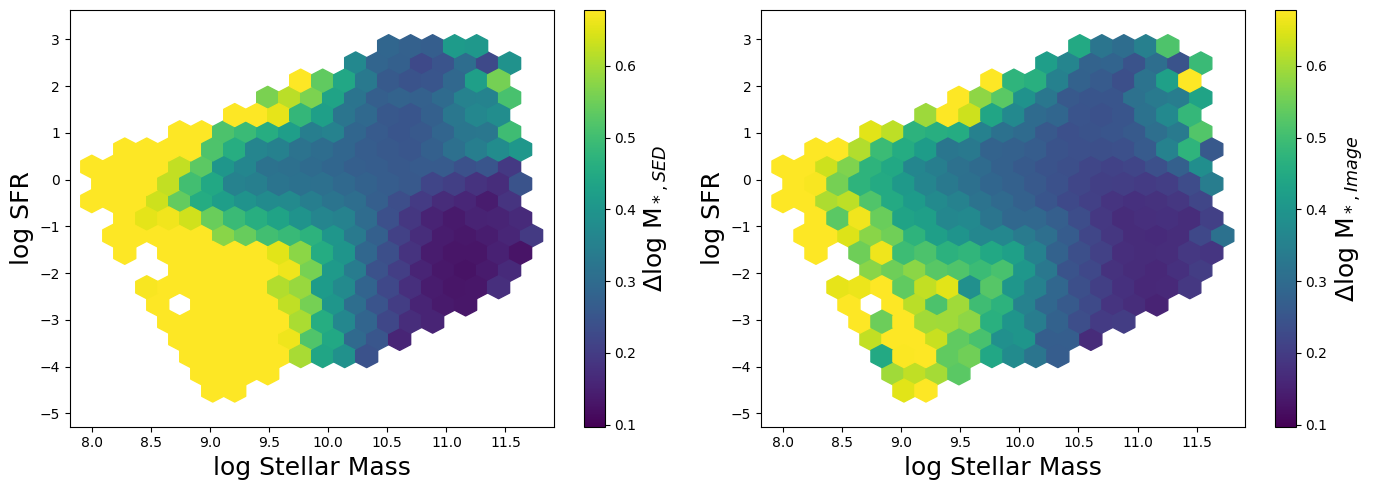

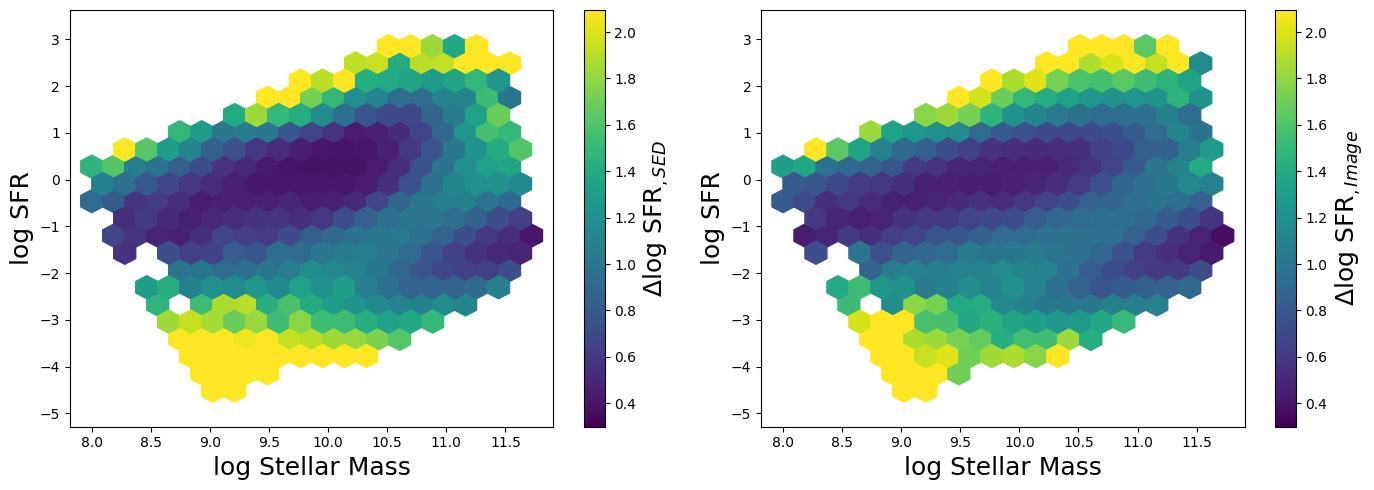

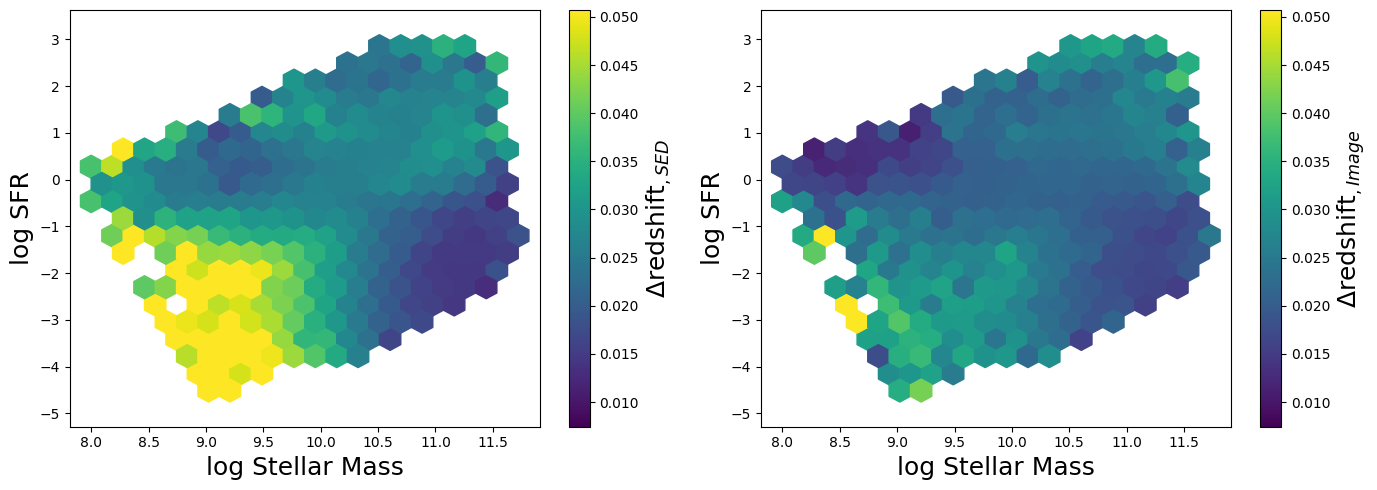

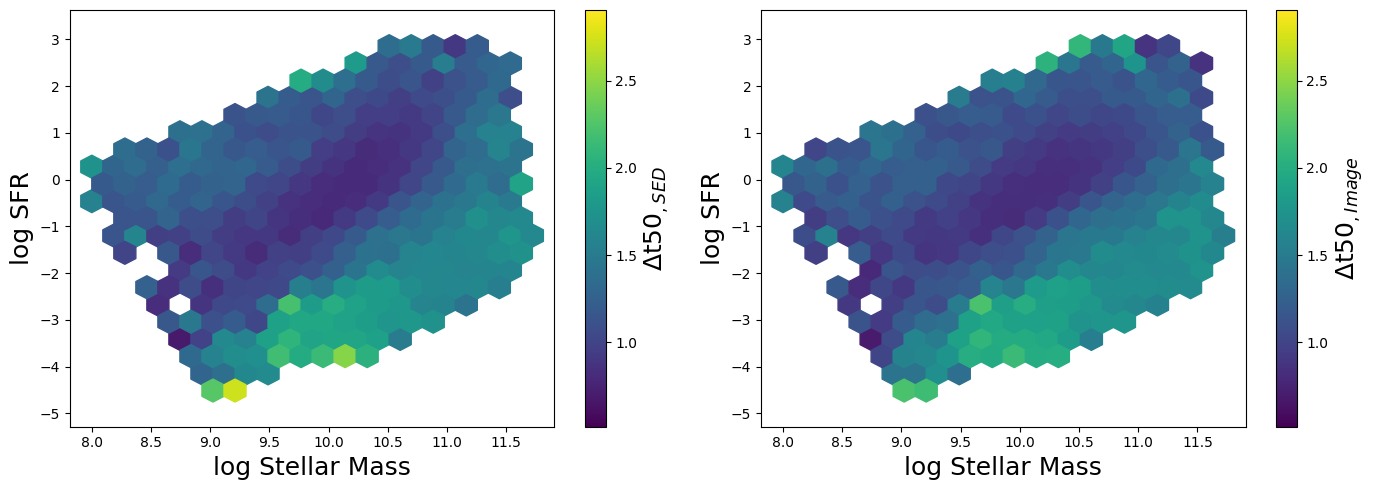

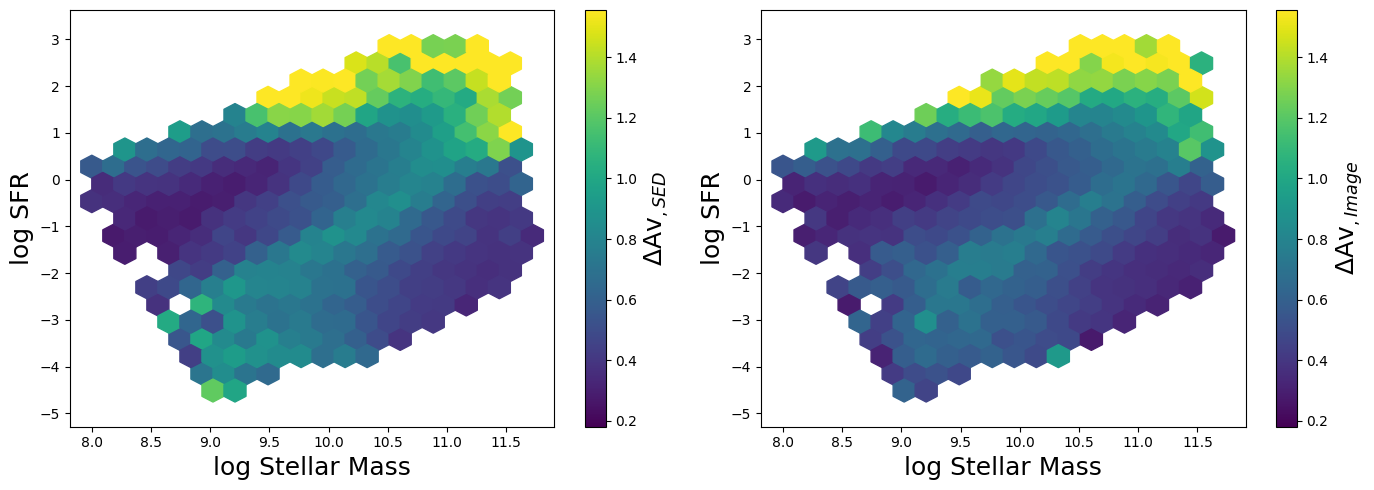

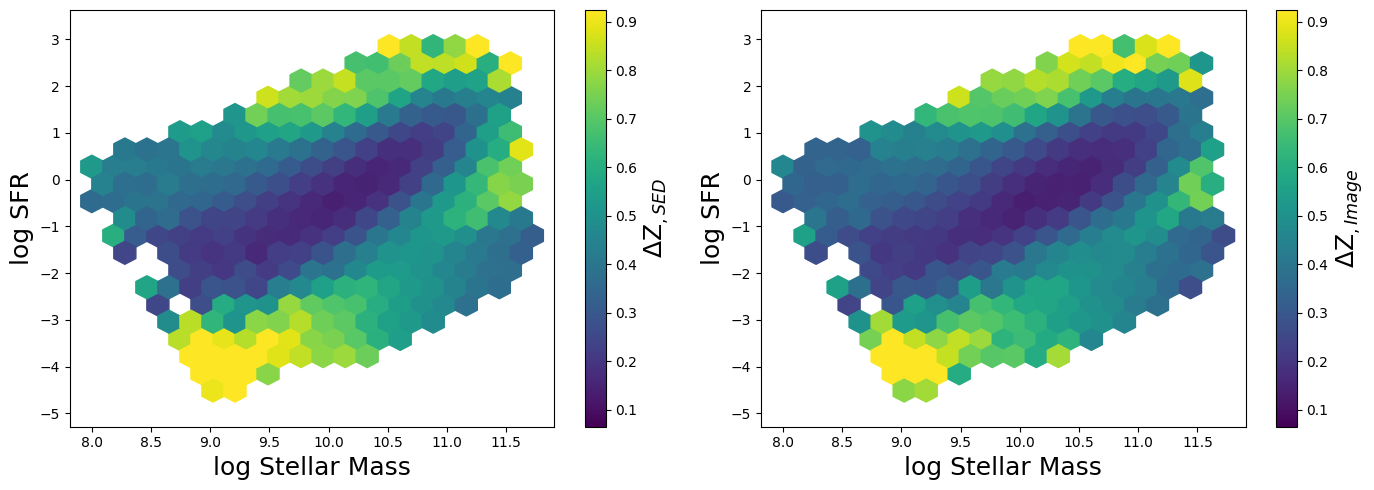

In [50]:
labels = ['log M$_*$', 'log SFR','redshift','t50','Av','Z']

mvals = theta[train_index:,0]
sfrvals = theta[train_index:,1] + theta[train_index:,0] - 9


for qty in range(6):
    c_lower_bound = np.percentile(allimerr[:,qty],2)
    c_upper_bound = np.percentile(allimerr[:,qty],98)
    plt.figure(figsize=(14,5))
    plt.subplot(1,2,1)
    plt.hexbin(mvals,sfrvals,gridsize=20,mincnt=2, C = allsederr_5_bands[:,qty], vmin=c_lower_bound, vmax=c_upper_bound, cmap='viridis')
    plt.xlabel('log Stellar Mass',fontsize=18); plt.ylabel('log SFR',fontsize=18)
    clbr = plt.colorbar()
    templim = plt.gci().get_clim()
    clbr.set_label('$\Delta$'+labels[qty]+'$_{,SED}$',fontsize=18)
    plt.subplot(1,2,2)
    plt.hexbin(mvals,sfrvals,gridsize=20,mincnt=2, C = allimerr[:,qty], vmin=c_lower_bound, vmax=c_upper_bound, cmap='viridis')
    plt.xlabel('log Stellar Mass',fontsize=18); plt.ylabel('log SFR',fontsize=18)
    clbr = plt.colorbar()
    clbr.set_label('$\Delta$'+labels[qty]+'$_{,Image}$',fontsize=18)
    plt.tight_layout()
    plt.show()

11 Band Photometry Accuracy

In [ ]:
from sklearn.metrics import r2_score
train_index = int(0.8*len(gswlc_data))
gal_ids = np.arange(train_index, len(gswlc_data))
ranges = [(9,12),(-15,-8),(0,1.0),(0,13.7),(0,3),(7.5,9.5)]
labels = ['log M$_*$', 'log sSFR','redshift','t50','Av','Z']

posteriors = all_samples_sed
# posteriors = []
truths = []

for gid in tqdm(gal_ids):
    # x = eleven_bands_SED
    # xobs = x[gid]
    # posterior_samples = posterior_ensemble_sed.sample((1000,), torch.Tensor(xobs).to(device), show_progress_bars=False)
    # posterior_samples = posterior_samples.cpu().numpy()
    # posteriors.append(np.array(posterior_samples))
    truths.append(theta[gid])

truth_array = np.array(truths)
truth_array.shape

for i in range(truth_array.shape[1]):
    plt.figure(figsize=(4,4))
    xax = truth_array[:,i]
    if labels[i] == 'log M$_*$':
        xax[xax > 12] = 12
    # if labels[i] == 'log sSFR':
    #     xax[xax>-7] = -7
    #     xax[xax<-15] = -15
    yax = np.array([np.nanpercentile(posteriors[j][:,i],50) for j in range(len(posteriors))])
    yax_lo = np.array([np.nanpercentile(posteriors[j][:,i],16) for j in range(len(posteriors))])
    yax_hi = np.array([np.nanpercentile(posteriors[j][:,i],84) for j in range(len(posteriors))])
    wts = ((np.nanmax(xax)-np.nanmin(xax))/(yax_hi-yax_lo))**2*1
    rsq = r2_score(xax, yax)
    bias = np.nanmedian(xax-yax)
    var = np.sqrt(np.nanstd((xax-yax)**2))
    plt.scatter(xax, yax, s = wts, c = wts, cmap='Spectral')
    # plt.scatter(xax,yax)
    plt.xlabel(labels[i]+' [true]',fontsize=18)
    plt.ylabel(labels[i]+' [pred]',fontsize=18)
    plt.plot([np.nanmin(xax), np.nanmax(xax)],[np.nanmin(xax), np.nanmax(xax)],'k--')
    xrange = np.nanmax(xax) - np.nanmin(xax)
    plt.text(np.nanmin(xax) + 0.03*xrange, np.nanmax(xax) -0.1*xrange, '$R^2: %.2f$' %rsq, fontsize=14)
    plt.text(np.nanmin(xax) + 0.03*xrange, np.nanmax(xax) -0.2*xrange, '$\mu: %.2f$' %bias, fontsize=14)
    plt.text(np.nanmin(xax) + 0.03*xrange, np.nanmax(xax) -0.3*xrange, '$\sigma: %.2f$' %var, fontsize=14)
    plt.show()

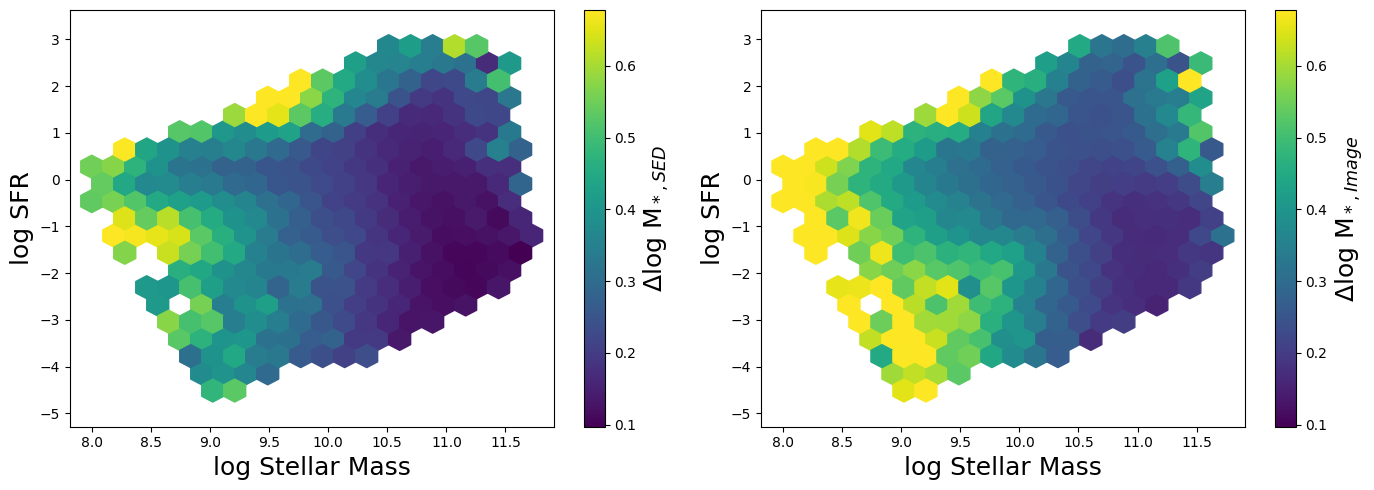

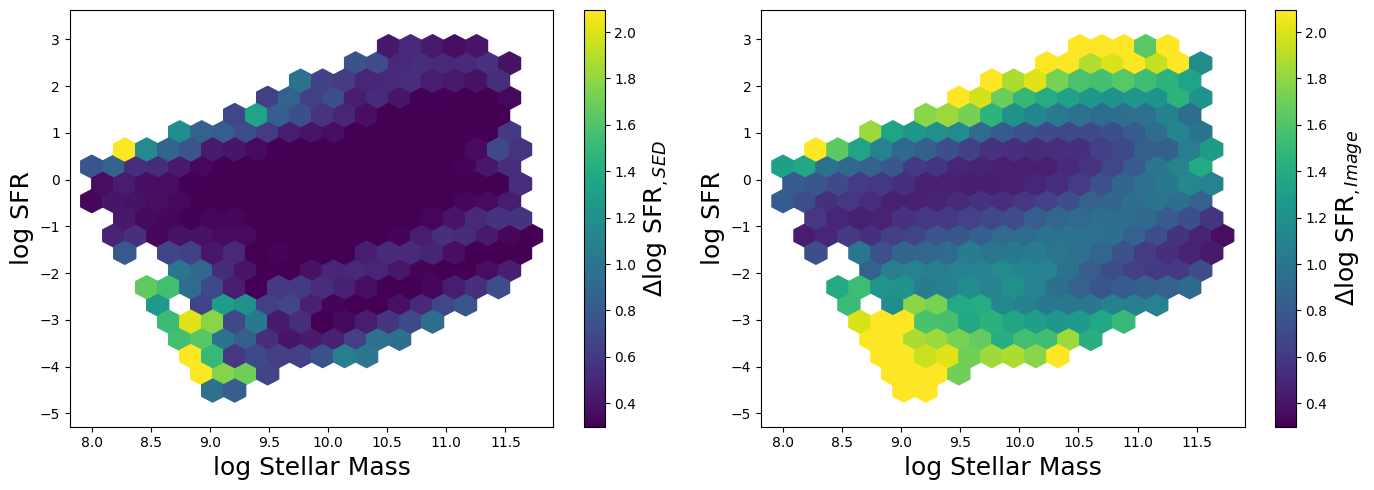

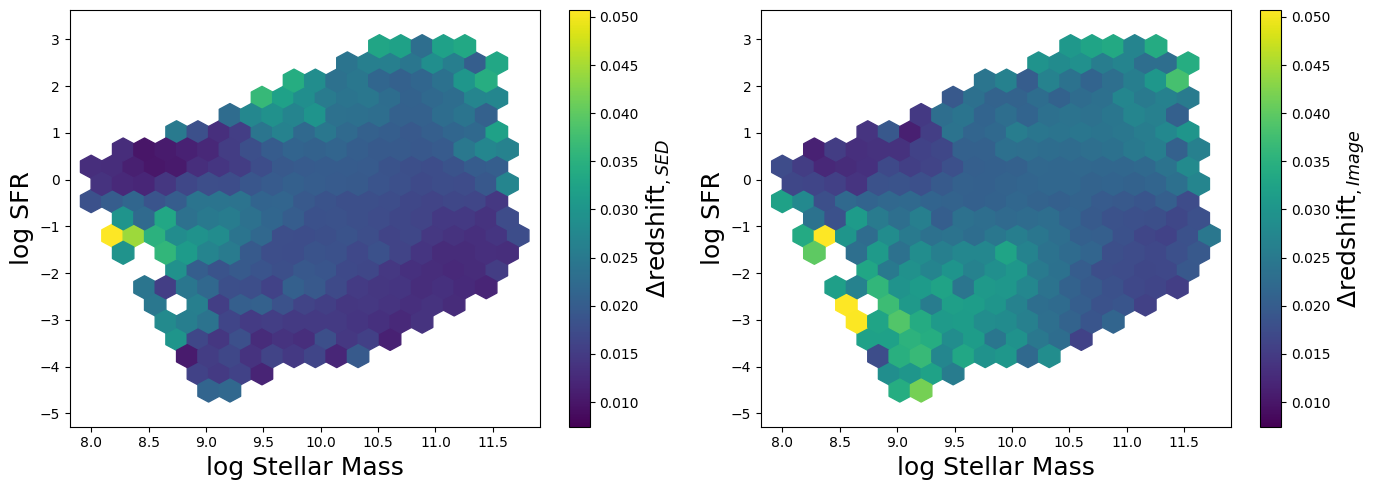

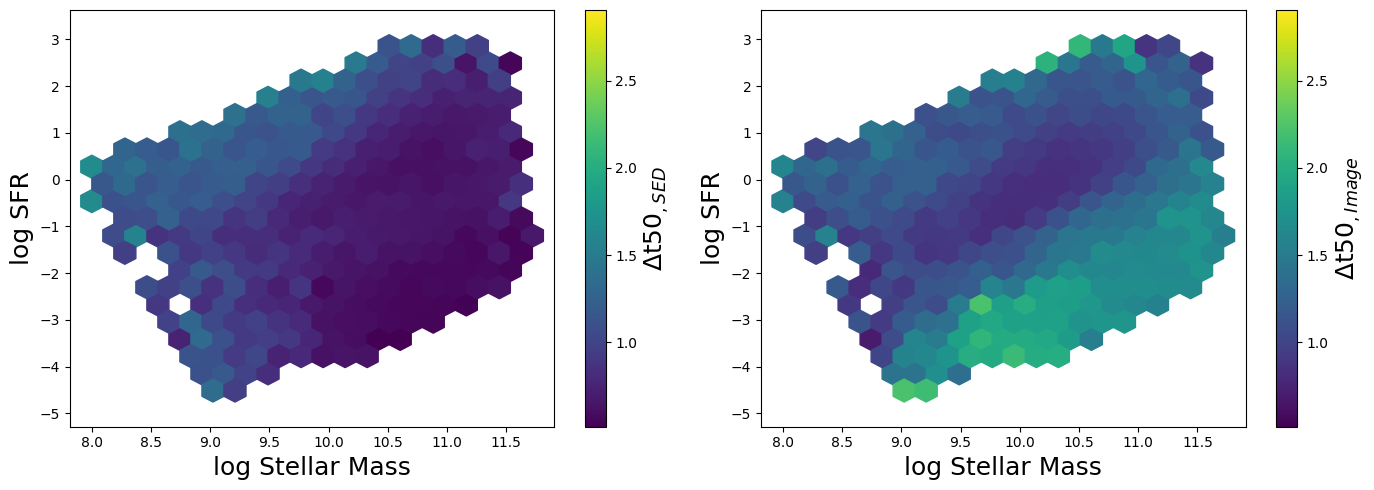

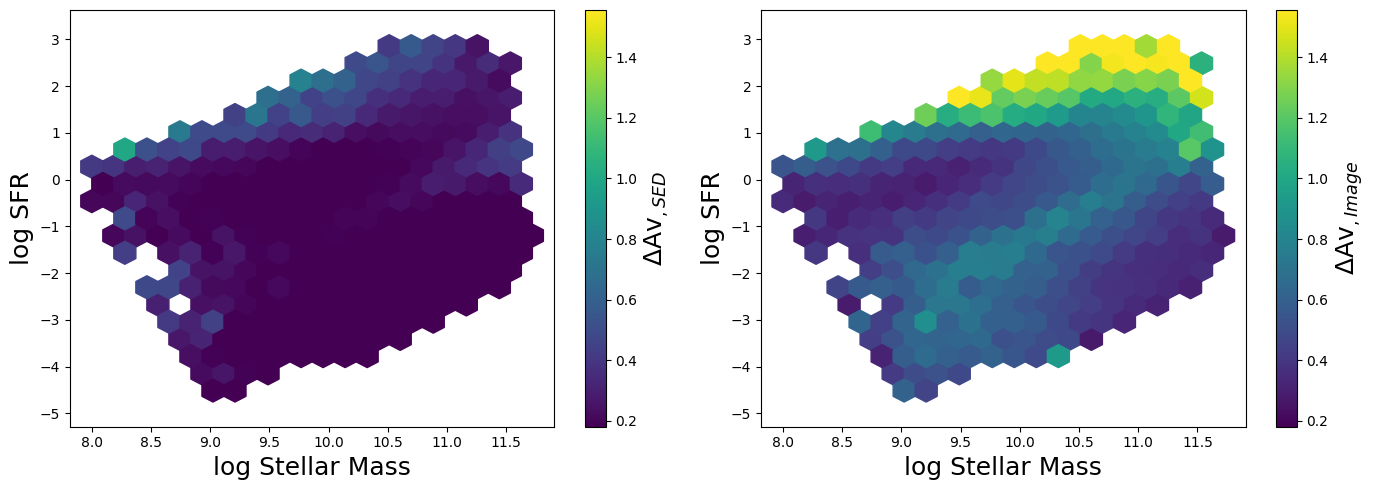

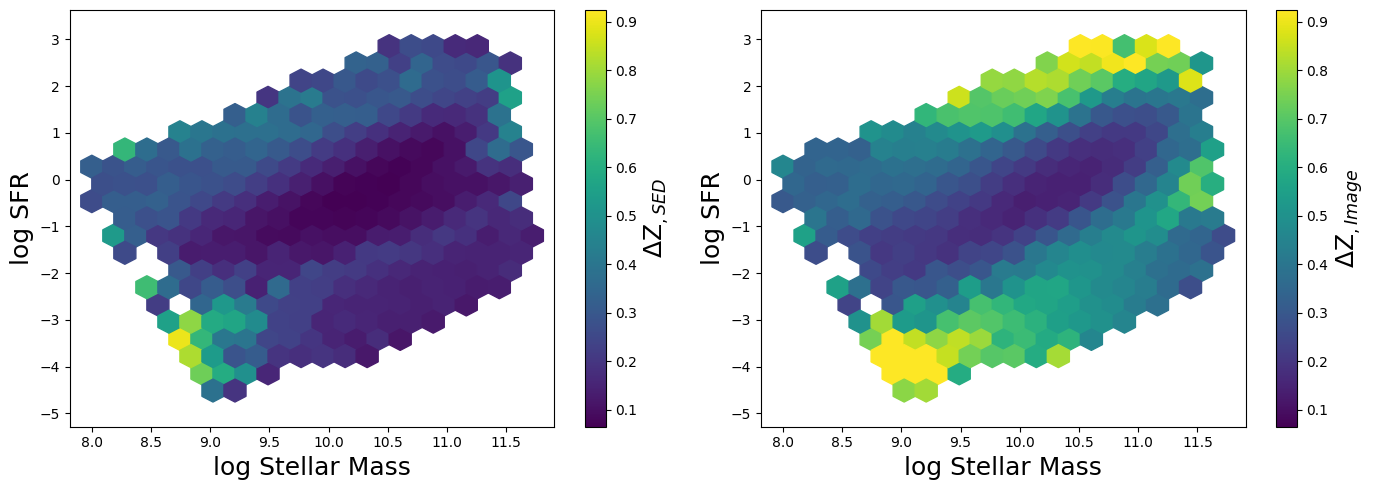

In [51]:
labels = ['log M$_*$', 'log SFR','redshift','t50','Av','Z']

mvals = theta[train_index:,0]
sfrvals = theta[train_index:,1] + theta[train_index:,0] - 9


for qty in range(6):
    c_lower_bound = np.percentile(allimerr[:,qty],2)
    c_upper_bound = np.percentile(allimerr[:,qty],98)
    plt.figure(figsize=(14,5))
    plt.subplot(1,2,1)
    plt.hexbin(mvals,sfrvals,gridsize=20,mincnt=2, C = allsederr_11_bands[:,qty], vmin=c_lower_bound, vmax=c_upper_bound, cmap='viridis')
    plt.xlabel('log Stellar Mass',fontsize=18); plt.ylabel('log SFR',fontsize=18)
    clbr = plt.colorbar()
    templim = plt.gci().get_clim()
    clbr.set_label('$\Delta$'+labels[qty]+'$_{,SED}$',fontsize=18)
    plt.subplot(1,2,2)
    plt.hexbin(mvals,sfrvals,gridsize=20,mincnt=2, C = allimerr[:,qty], vmin=c_lower_bound, vmax=c_upper_bound, cmap='viridis')
    plt.xlabel('log Stellar Mass',fontsize=18); plt.ylabel('log SFR',fontsize=18)
    clbr = plt.colorbar()
    clbr.set_label('$\Delta$'+labels[qty]+'$_{,Image}$',fontsize=18)
    plt.tight_layout()
    plt.show()

# Figure 3

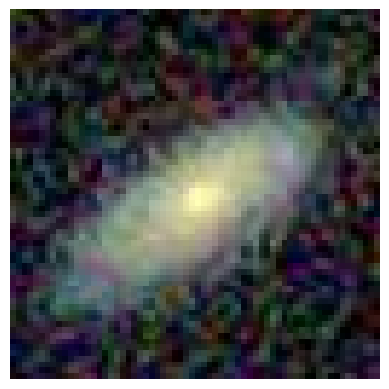

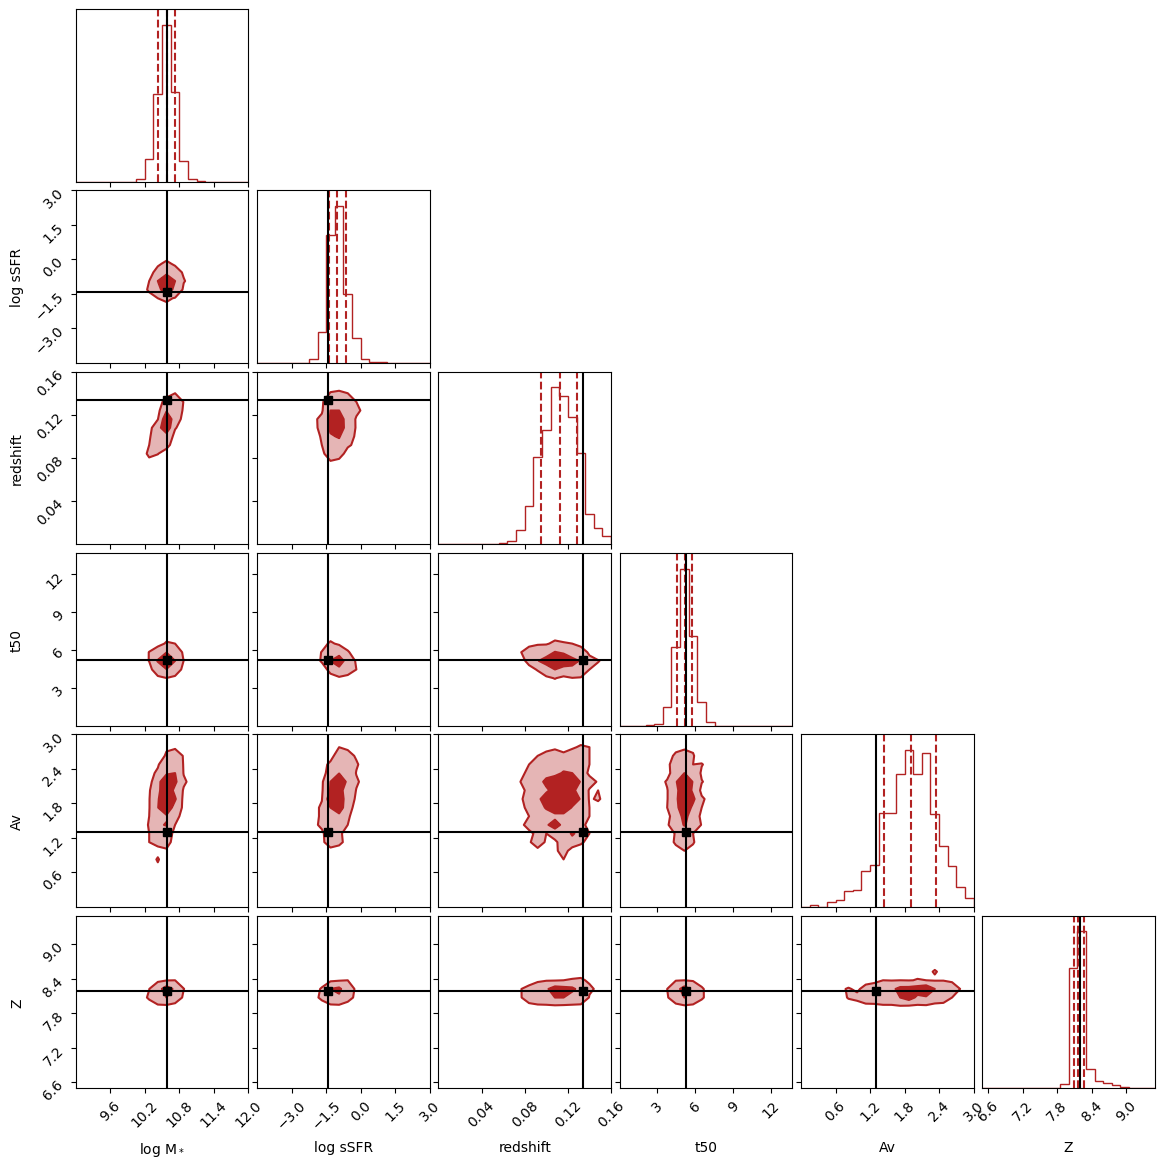

In [28]:
clrs = plt.cm.Spectral(np.linspace(0,1,10))
ranges = [(9,12),(-4.5,3),(0,0.16),(0,13.7),(0,3),(6.5,9.5)]
labels = ['log M$_*$', 'log sSFR','redshift','t50','Av','Z']

np.random.seed(256)
random_gal = np.random.randint(train_index, len(gswlc_data), size=(1))
random_gal = np.array(random_gal[0],dtype=int)

gid = random_gal

xobs_im = gswlc_embeds[gid,:]
x_truth = theta[gid,:]

posterior_samples_im = posterior_ensemble_im.sample((1000,), torch.Tensor(xobs_im).to(device), show_progress_bars = False)
posterior_samples_im = posterior_samples_im.cpu().numpy()

plt.imshow(Image.open(io.BytesIO(gswlc_images[gid])))
plt.axis('off')

fig = corner.corner(posterior_samples_im, truths=x_truth, truth_color='k',color='firebrick',range=ranges,labels=labels, plot_datapoints=False, fill_contours=True,quantiles=(0.16, 0.5, 0.84),levels=[1 - np.exp(-(1/1)**2/2),1 - np.exp(-(2/1)**2/2)])
fig.set_size_inches(12,12)
plt.show()

# Figure 4

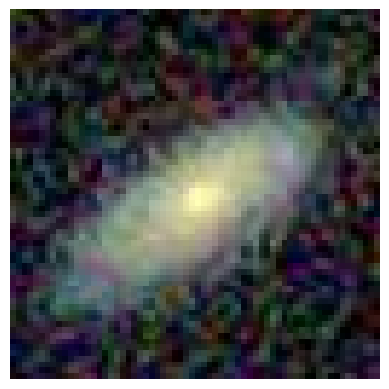

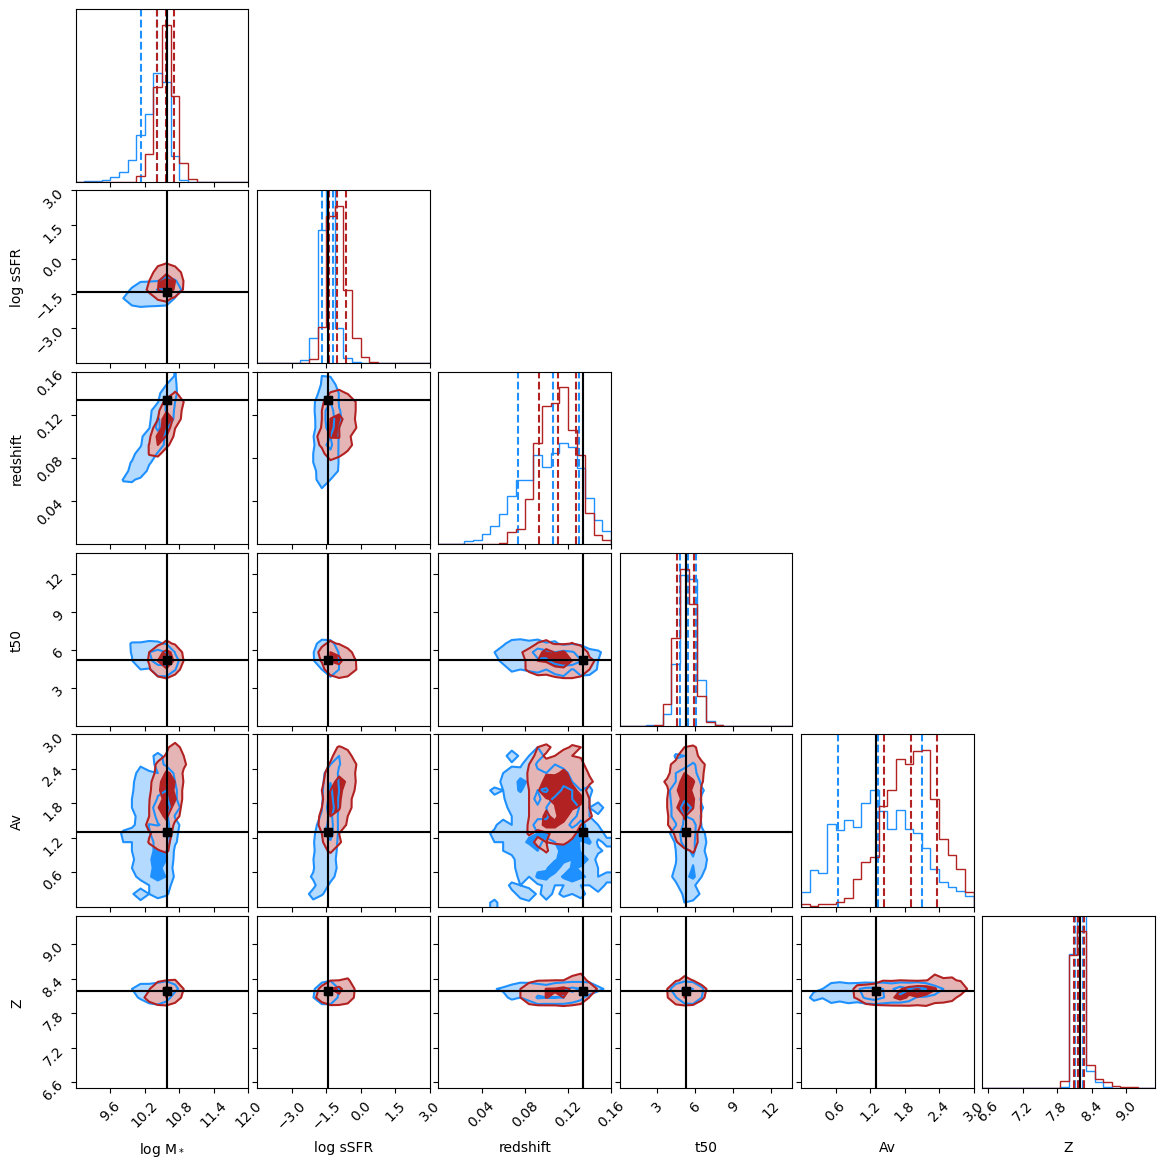

In [29]:
clrs = plt.cm.Spectral(np.linspace(0,1,10))
ranges = [(9,12),(-4.5,3),(0,0.16),(0,13.7),(0,3),(6.5,9.5)]
labels = ['log M$_*$', 'log sSFR','redshift','t50','Av','Z']


np.random.seed(256)
random_gal = np.random.randint(train_index, len(gswlc_data), size=(1))
random_gal = np.array(random_gal[0],dtype=int)

gid = random_gal
xobs_sed = five_bands_SED[gid,:]
xobs_im = gswlc_embeds[gid,:]
x_truth = theta[gid,:]

posterior_samples_sed = posterior_ensemble_sed_5_bands.sample((1000,), torch.Tensor(xobs_sed).to(device), show_progress_bars = False)
posterior_samples_sed = posterior_samples_sed.cpu().numpy()


posterior_samples_im = posterior_ensemble_im.sample((1000,), torch.Tensor(xobs_im).to(device), show_progress_bars = False)
posterior_samples_im = posterior_samples_im.cpu().numpy()

plt.imshow(Image.open(io.BytesIO(gswlc_images[gid])))
plt.axis('off')

fig = corner.corner(posterior_samples_sed, truths=x_truth,color='dodgerblue',range=ranges,labels=labels, plot_datapoints=False, fill_contours=True,quantiles=(0.16, 0.5, 0.84),levels=[1 - np.exp(-(1/1)**2/2),1 - np.exp(-(2/1)**2/2)])
fig = corner.corner(posterior_samples_im, truths=x_truth, truth_color='k',color='firebrick',range=ranges,labels=labels,fig=fig, plot_datapoints=False, fill_contours=True,quantiles=(0.16, 0.5, 0.84),levels=[1 - np.exp(-(1/1)**2/2),1 - np.exp(-(2/1)**2/2)])
fig.set_size_inches(12,12)
plt.show()

# Figure 5

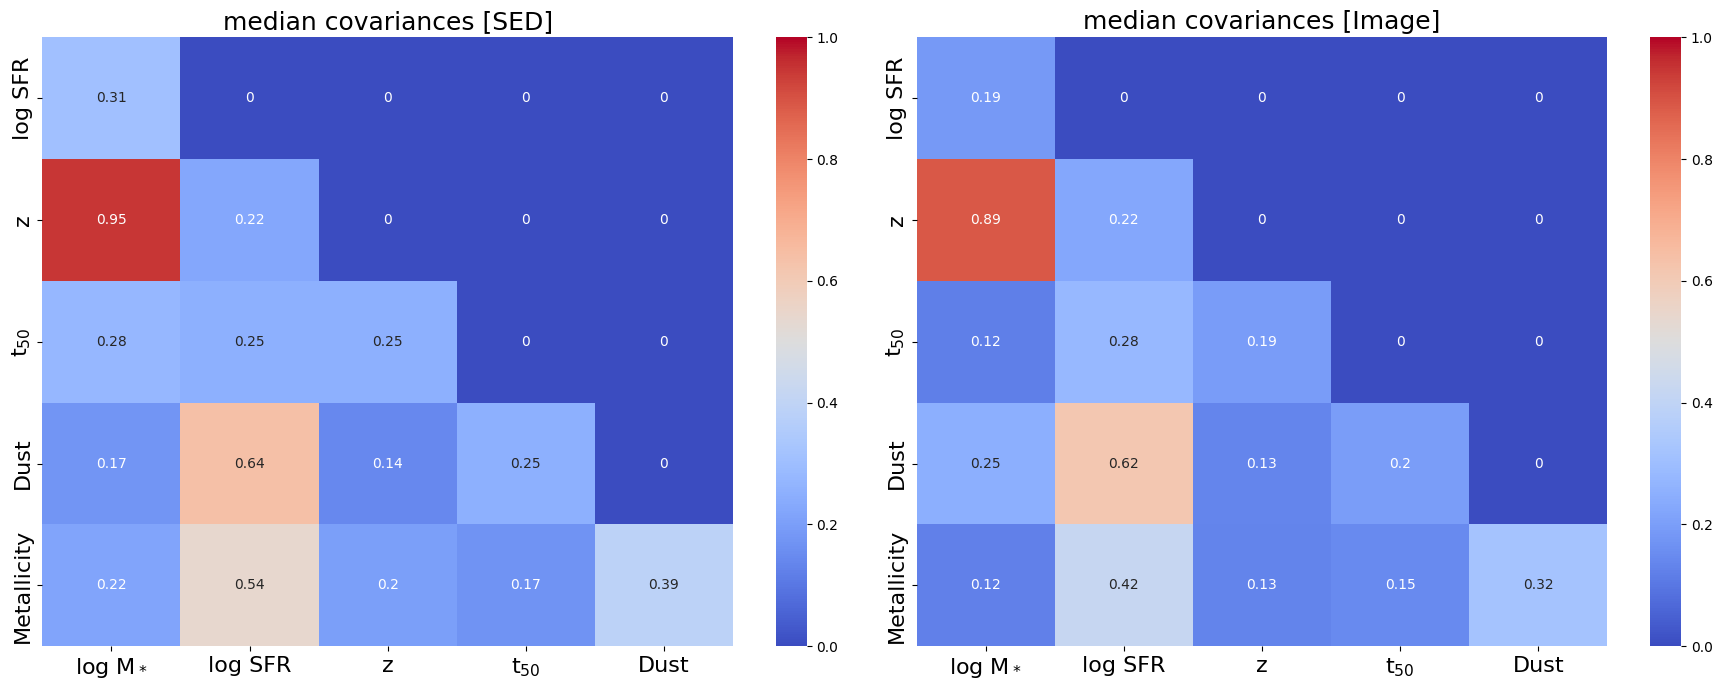

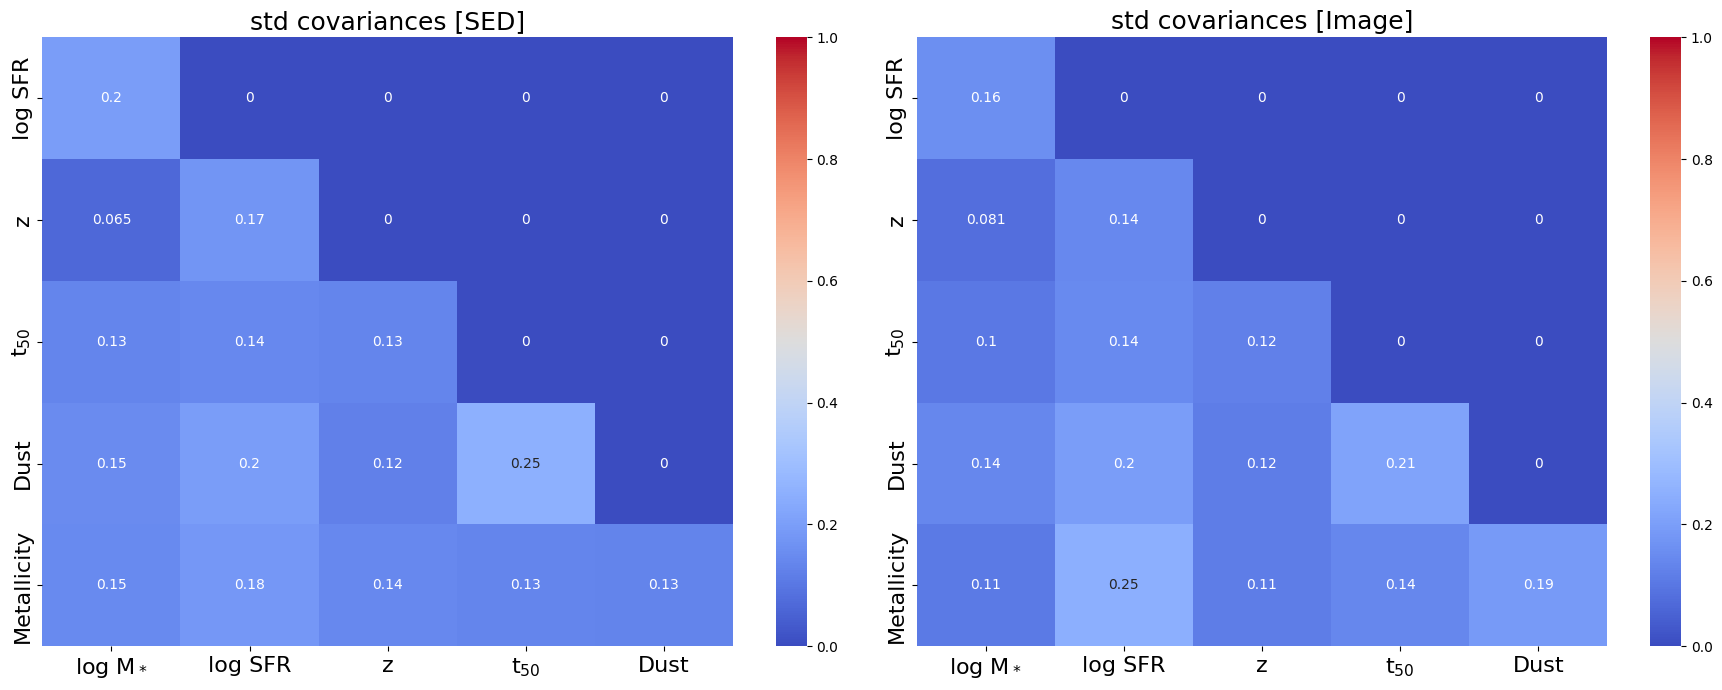

In [30]:
import seaborn as sns
labels = ['log M$_*$', 'log SFR','z','t$_{50}$','Dust','Metallicity']

target_sed = cov_array_sed_5_bands

plt.figure(figsize=(9*2,7))
plt.subplot(1,2,1)

sns.heatmap(np.nanmedian(np.abs(target_sed),0), cmap='coolwarm',vmin=0., vmax=1., annot=True , cbar=True)
plt.xticks(np.arange(5)+0.5, labels[0:5], fontsize=16)
plt.yticks(np.arange(5)+0.5, labels[1:], fontsize=16)
plt.title('median covariances [SED]',fontsize=18)
 
plt.subplot(1,2,2)

sns.heatmap(np.nanmedian(np.abs(cov_array_im),0), cmap='coolwarm',vmin=0., vmax=1., annot=True , cbar=True)
plt.xticks(np.arange(5)+0.5, labels[0:5], fontsize=16)
plt.yticks(np.arange(5)+0.5, labels[1:], fontsize=16)
plt.title('median covariances [Image]',fontsize=18)

plt.tight_layout()
plt.show()

plt.figure(figsize=(9*2,7))
plt.subplot(1,2,1)

sns.heatmap(np.nanstd(np.abs(target_sed),0), cmap='coolwarm',vmin=0., vmax=1., annot=True , cbar=True)
plt.xticks(np.arange(5)+0.5, labels[0:5], fontsize=16)
plt.yticks(np.arange(5)+0.5, labels[1:], fontsize=16)
plt.title('std covariances [SED]',fontsize=18)

plt.subplot(1,2,2)

sns.heatmap(np.nanstd(np.abs(cov_array_im),0), cmap='coolwarm',vmin=0., vmax=1., annot=True , cbar=True)
plt.xticks(np.arange(5)+0.5, labels[0:5], fontsize=16)
plt.yticks(np.arange(5)+0.5, labels[1:], fontsize=16)
plt.title('std covariances [Image]',fontsize=18)

plt.tight_layout()
plt.show()

# Figure 6

66 0.03852889667250438
3.66
4.205


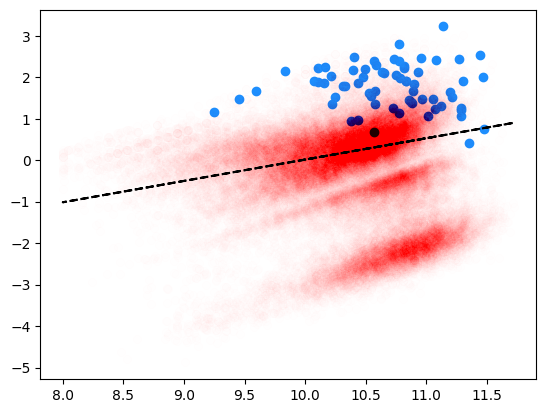

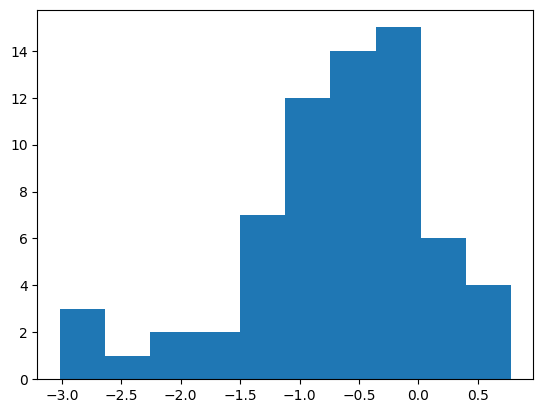

In [75]:
#Very Dusty Galaxies
better_img = np.where((np.array(theta)[train_index:][:,4]>3.5)  & (allsederr_5_bands[:,1]-allimerr_5_bands[:,1]>0)  & (allsederr_5_bands[:,3]-allimerr_5_bands[:,3]>0) & (allsederr_5_bands[:,4]-allimerr_5_bands[:,4]>0) & (allsederr_5_bands[:,5]-allimerr_5_bands[:,5]>0))[0]
better_sed = np.where((np.array(theta)[train_index:][:,4]>3.5) & (allsederr_5_bands[:,1]-allimerr_5_bands[:,1]<0) & (allsederr_5_bands[:,3]-allimerr_5_bands[:,3]<0) & (allsederr_5_bands[:,4]-allimerr_5_bands[:,4]<0) & (allsederr_5_bands[:,5]-allimerr_5_bands[:,5]<0))[0]
print(len(better_img), len(better_img)/len(np.where(theta[train_index:][:,4]>3)[0]))
plt.scatter(mvals[better_img], sfrvals[better_img], color='dodgerblue', alpha=1)
# plt.scatter(mvals[better_sed], sfrvals[better_sed], color='green', alpha=1)
plt.scatter(mvals, sfrvals, color='red', alpha=0.005)
plt.plot(mvals, (0.84-0.026*12.5)*mvals - (6.51-0.11*12.5), color='k', linestyle='--')

plt.figure()
plt.hist(allsederr[:,1][better_img]-allimerr[:,1][better_img])
# print(len(np.where(allsederr[:,1][better_img]-allimerr[:,1][better_img]>0)[0]))
print(np.nanmean(sersic_n[better_img]))
print(np.nanmean(sersic_n[better_sed]))

In [ ]:
selected_sample = better_img
plt.subplots(int(np.sqrt(len(selected_sample))),int(np.sqrt(len(selected_sample))),figsize=(20,20))
for i in range(len(selected_sample)):
    j = selected_sample[i] + train_index
    plt.subplot(int(np.sqrt(len(selected_sample))),int(np.sqrt(len(selected_sample))),i+1)
    # plt.title('Sersic n: '+str(sersic_n[j-train_index])[0:4])
    # plt.title('Pmerger: '+str(pmerger[j-train_index])[0:4])
    plt.imshow(Image.open(io.BytesIO(gswlc_images[j])))
    plt.axis('off')
        # plt.show()

plt.show();

# Figure 7

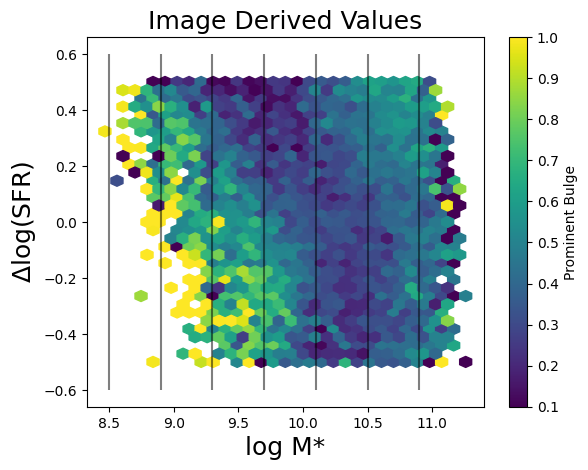

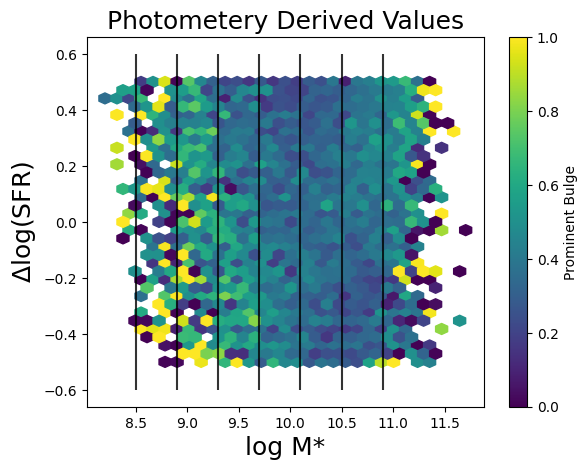

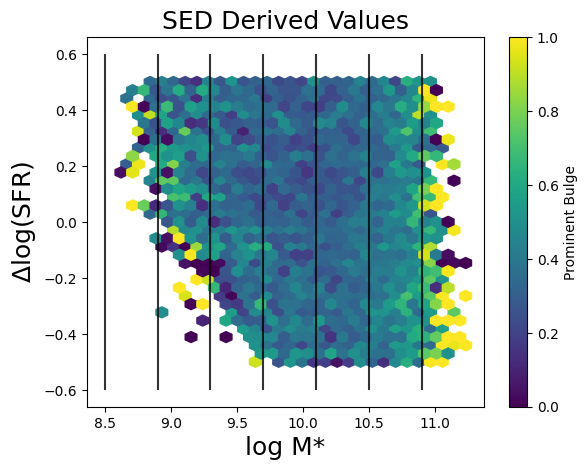

In [39]:
lower_bound_mass = 10
upper_mound_mass = 11

main_sequence_sfr_sed = (0.84-0.026*12.5)*allsedpred_5_bands[:,0] - (6.51-0.11*12.5)
main_sequence_sfr_im = (0.84-0.026*12.5)*allimpred[:,0] - (6.51-0.11*12.5)
main_sequence_sfr_true= (0.84-0.026*12.5)*theta[train_index:,0] - (6.51-0.11*12.5)

sfr_vals_im = allimpred[:,1]+allimpred[:,0]-9
sfr_vals_sed = allsedpred_5_bands[:,1]+allsedpred_5_bands[:,0]-9
sfr_vals_true = theta[train_index:,1]+theta[train_index:,0]-9

mvals_im= allimpred[:,0]
mvals_sed = allsedpred_5_bands[:,0]
mvals_true = theta[train_index:,0]


mask_sed = np.where((sfr_vals_sed>=main_sequence_sfr_sed-0.5)&((sfr_vals_sed<=main_sequence_sfr_sed+0.5)))[0]


mask_im = np.where((sfr_vals_im>=main_sequence_sfr_im-0.5)&((sfr_vals_im<=main_sequence_sfr_im+0.5)))[0]


mask_true = np.where((sfr_vals_true>=main_sequence_sfr_true-0.5)&((sfr_vals_true<=main_sequence_sfr_true+0.5)))[0]

#Calculate scatter from sfms for 11 band SED and images
scatter_5_band_sed = sfr_vals_sed - main_sequence_sfr_sed
scatter_im = sfr_vals_im - main_sequence_sfr_im
scatter_true = sfr_vals_true - main_sequence_sfr_true

mass_bins = np.arange(8.5,11,0.4)

plt.figure()
plt.title('Image Derived Values',fontsize=18)
plt.hexbin(mvals_im[mask_im],scatter_im[mask_im], C = pbulge[mask_im], gridsize=30, cmap='viridis', vmin=0.1, vmax=1)
plt.vlines(mass_bins, -0.6, 0.6, color='black', alpha=0.5)
# plt.hlines(0, 8.5, 11.5, color='black', alpha=0.8, linestyle='--')
plt.xlabel('log M*',fontsize=18)
plt.ylabel('$\Delta$log(SFR)',fontsize=18)
plt.colorbar(label='Prominent Bulge')

plt.figure()
plt.title('Photometery Derived Values',fontsize=18)
plt.hexbin(mvals_true[mask_true],scatter_true[mask_true], C = pbulge[mask_true], gridsize=30, cmap='viridis', vmin=0, vmax=1)
plt.vlines(mass_bins, -0.6, 0.6, color='black', alpha=0.8)
plt.xlabel('log M*',fontsize=18)
plt.ylabel('$\Delta$log(SFR)',fontsize=18)
plt.colorbar(label='Prominent Bulge')


plt.figure()
plt.title('SED Derived Values',fontsize=18)
plt.hexbin(mvals_sed[mask_sed],scatter_5_band_sed[mask_sed], C = pbulge[mask_sed], gridsize=30, cmap='viridis', vmin=0, vmax=1)
plt.vlines(mass_bins, -0.6, 0.6, color='black', alpha=0.8)
plt.xlabel('log M*',fontsize=18)
plt.ylabel('$\Delta$log(SFR)',fontsize=18)
plt.colorbar(label='Prominent Bulge')

In [80]:
np.shape(gswlc_embeds[0])

(768,)

# Figure 8

In [ ]:
merger = np.where(pmerger<=0.1)[0]

selected_sample = merger[:100]
plt.subplots(int(np.sqrt(len(selected_sample))),int(np.sqrt(len(selected_sample))),figsize=(20,20))
for i in range(len(selected_sample)):
    j = selected_sample[i] + train_index
    plt.subplot(int(np.sqrt(len(selected_sample))),int(np.sqrt(len(selected_sample))),i+1)
    # plt.title('Sersic n: '+str(sersic_n[j-train_index])[0:4])
    plt.title('Pmerger: '+str(pmerger[j-train_index])[0:4])
    plt.imshow(Image.open(io.BytesIO(gswlc_images[j])))
    plt.axis('off')
        # plt.show()

plt.show();

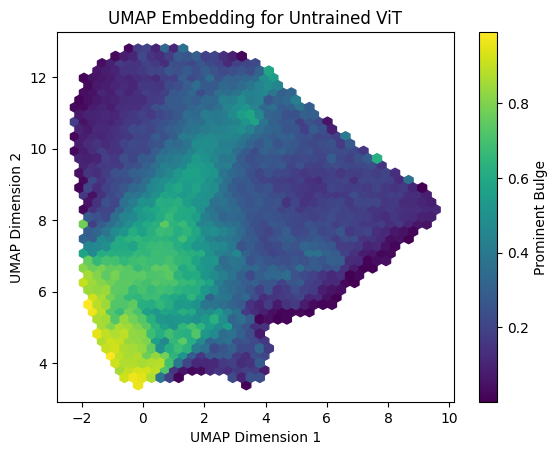

In [53]:
import umap
# data = np.array(gswlc_embeds)
## Create UMAP reducer
# reducer = umap.UMAP()

## Fit and transform the data
# embedding = reducer.fit_transform(data)11

# Visualize the embedding (if you want 2D)
plt.hexbin(embedding[:, 0], embedding[:, 1], C = gswlc_data_merged['pmerger_morph'], gridsize=40) 
plt.title("UMAP Embedding for Untrained ViT")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.colorbar(label='Prominent Bulge')
plt.show()